# Task 3 — OOF error audit of the selected spending model

Analysis-only notebook. Reconstruct the selected `t3_gate_blend_cv5_v2` predictions from its five saved **development out-of-fold** files and model cards. Each row is predicted by models fitted without that row. The original 20% holdout has already been reused for several comparisons, so development OOF is the main diagnostic source. This notebook reads no Test data, fits no models, creates no features, and writes no new dataset artifact. Scores are MAE in THB, not competition NMAE.

In [1]:
from pathlib import Path
import json,sys
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents)
          if (p/"src"/"pipeline"/"save_data.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.pipeline.random_seed import set_seed
SEED=set_seed()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split,StratifiedKFold
sns.set_theme(style="whitegrid")
SRC=ROOT/"src"
TASK=SRC/"task3"
TARGET,ID="spending_30d","player_id"
DATA_NAME="eda_combined_v1"
card=json.loads((TASK/"data"/"eda"/f"{DATA_NAME}.json").read_text(encoding="utf-8"))
train=pd.read_parquet(SRC/card["splits"]["train"]["path"])
assert train[ID].is_unique and train[TARGET].notna().all()
y=train[TARGET].astype(float)
bands=pd.cut(y,bins=[-1,0,100,1000,10000,50000,np.inf],labels=False)
dev_idx,valid_idx=train_test_split(np.arange(len(y)),test_size=.20,
    stratify=bands,random_state=SEED)
dev=train.iloc[dev_idx].reset_index(drop=True)
dev_bands=bands.iloc[dev_idx].reset_index(drop=True)
splits=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(dev,dev_bands))
SAVE=TASK/"save"
RESULTS=TASK/"models"/"results"
def model_card(name):
    return json.loads((SAVE/f"{name}.json").read_text(encoding="utf-8"))
gate_weight=float(model_card("t3_gate_blend_cv5_v2")["card"]["gate_weight"])
cat_weight=float(model_card("t3_cat_lgb_blend_cv5_v2")["card"]["catboost_weight"])
gate_threshold=float(model_card("t3_positive_gate_cv5_v2")["card"]["threshold"])
print("Labeled development rows:",len(dev),"holdout rows reserved from this audit:",len(valid_idx))
print("Weights gate/blend:",gate_weight,cat_weight,"gate threshold:",gate_threshold)

Labeled development rows: 83200 holdout rows reserved from this audit: 20800
Weights gate/blend: 0.8 0.4 gate threshold: 0.5


## 1. Reconstruct and verify the five OOF folds

In [2]:
parts=[]
for fold,(_,check_pos) in enumerate(splits,1):
    gate_path=RESULTS/f"round3_gate_fold{fold}_v1.parquet"
    blend_path=RESULTS/f"round3_blend_fold{fold}_v1.parquet"
    gate_meta=json.loads((RESULTS/f"round3_gate_fold{fold}_v1.json").read_text(encoding="utf-8"))
    blend_meta=json.loads((RESULTS/f"round3_blend_fold{fold}_v1.json").read_text(encoding="utf-8"))
    assert gate_meta["key"]["dataset"]==DATA_NAME and blend_meta["key"]["dataset"]==DATA_NAME
    assert gate_meta["key"]["dataset_created_at"]==card["created_at"]
    assert blend_meta["key"]["dataset_created_at"]==card["created_at"]
    gate=pd.read_parquet(gate_path)
    blend=pd.read_parquet(blend_path)
    assert gate.row_pos.tolist()==check_pos.tolist()==blend.row_pos.tolist()
    assert gate.true.equals(blend.true)
    positive=np.maximum(gate.positive_amount,0)
    gate_pred=np.where(gate.probability>=gate_threshold,positive,0)
    blend_pred=np.maximum(cat_weight*blend.cat+(1-cat_weight)*blend.lgb,0)
    prediction=gate_weight*gate_pred+(1-gate_weight)*blend_pred
    parts.append(pd.DataFrame({"fold":fold,"row_pos":check_pos,"true":gate.true,
        "probability_nonzero":gate.probability,"positive_amount":positive,
        "gate_prediction":gate_pred,"blend_prediction":blend_pred,
        "prediction":prediction}))
oof=pd.concat(parts,ignore_index=True).sort_values("row_pos").reset_index(drop=True)
assert len(oof)==len(dev) and oof.row_pos.is_unique
assert np.array_equal(oof.row_pos,np.arange(len(dev)))
assert np.array_equal(oof.true,dev[TARGET])
assert np.isfinite(oof[["probability_nonzero","positive_amount","prediction"]].to_numpy()).all()
oof["absolute_error"]=(oof.prediction-oof.true).abs()
oof["signed_error"]=oof.prediction-oof.true
oof["actual_nonzero"]=oof.true.gt(0)
oof["gate_nonzero"]=oof.probability_nonzero.ge(gate_threshold)
fold_scores=oof.groupby("fold").apply(
    lambda g:mean_absolute_error(g.true,g.prediction),include_groups=False)
display(fold_scores.rename("MAE_thb").to_frame().round(2))
print("Mean fold MAE:",round(fold_scores.mean(),2),"pooled OOF MAE:",round(oof.absolute_error.mean(),2))
assert abs(fold_scores.mean()-2895.92)<.2

,MAE_thb
fold,
1,2815.58
2,2973.69
3,2797.07
4,2929.51
5,2963.76


Mean fold MAE: 2895.92 pooled OOF MAE: 2895.92


## 2. Where does absolute error accumulate?

Report both number of rows and share of total absolute error. A small tail can dominate MAE even when its group count is low.

,accounts,mean_target,mean_prediction,MAE_thb,total_absolute_error,underprediction_rate,row_share_pct,error_share_pct
target_band,,,,,,,,
zero,40039,0.00,1927.89,1927.89,7.719067e+07,0.00,48.12,32.04
"(0,100]",2006,51.97,8.77,50.51,1.013165e+05,0.92,2.41,0.04
"(100,1k]",11291,416.98,127.89,315.33,3.560373e+06,0.91,13.57,1.48
"(1k,10k]",18608,3006.82,2809.15,584.49,1.087620e+07,0.61,22.37,4.51
"(10k,50k]",4470,31148.46,32990.04,4653.17,2.079968e+07,0.39,5.37,8.63
50k+,6786,99423.84,89462.24,18923.14,1.284124e+08,0.59,8.16,53.30


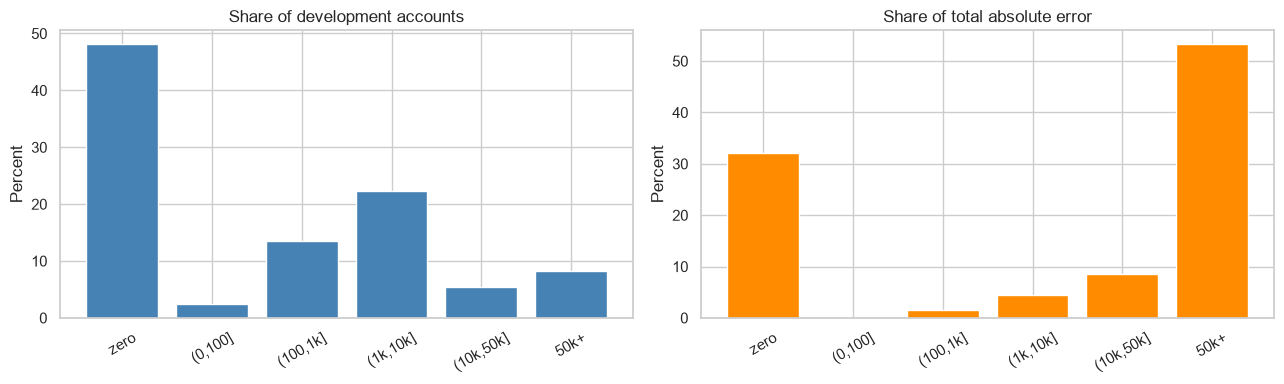

In [3]:
BAND_EDGES=[-1,0,100,1000,10000,50000,np.inf]
BAND_LABELS=["zero","(0,100]","(100,1k]","(1k,10k]","(10k,50k]","50k+"]
oof["target_band"]=pd.cut(oof.true,bins=BAND_EDGES,labels=BAND_LABELS)
band_table=(oof.groupby("target_band",observed=True)
    .agg(accounts=("true","size"),mean_target=("true","mean"),
         mean_prediction=("prediction","mean"),
         MAE_thb=("absolute_error","mean"),
         total_absolute_error=("absolute_error","sum"),
         underprediction_rate=("signed_error",lambda x:(x<0).mean())))
band_table["row_share_pct"]=100*band_table.accounts/len(oof)
band_table["error_share_pct"]=100*band_table.total_absolute_error/oof.absolute_error.sum()
display(band_table.round(2))
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].bar(band_table.index.astype(str),band_table.row_share_pct,color="steelblue")
axes[0].set(title="Share of development accounts",ylabel="Percent")
axes[1].bar(band_table.index.astype(str),band_table.error_share_pct,color="darkorange")
axes[1].set(title="Share of total absolute error",ylabel="Percent")
for ax in axes: ax.tick_params(axis="x",labelrotation=30)
plt.tight_layout();plt.show()

## 3. The nonzero gate's costly mistakes

The final mixture retains a 20% continuous blend, so a gate-off row may still receive a positive final prediction. “False nonzero” and “false zero” below refer **only to the gate decision**, while error is measured on the final mixture.

,accounts,MAE_thb,total_absolute_error,mean_final_prediction,row_share_pct,error_share_pct
gate_case,,,,,,
true_nonzero_gate_on,30485,5172.52,1.576843e+08,26509.16,36.64,65.45
false_nonzero_gate_on,10849,7097.27,7.699832e+07,7097.27,13.04,31.96
false_zero_gate_off,12676,478.52,6.065713e+06,12.53,15.24,2.52
true_zero_gate_off,29190,6.59,1.923482e+05,6.59,35.08,0.08


,accounts,observed_nonzero_rate,mean_probability
probability_bin,,,
"(0.1, 0.2]",1986,0.210,0.189
"(0.2, 0.3]",22041,0.224,0.233
"(0.3, 0.4]",7487,0.395,0.372
"(0.4, 0.5]",10352,0.422,0.433
"(0.5, 0.6]",10203,0.563,0.555
"(0.6, 0.7]",9850,0.662,0.658
"(0.7, 0.8]",6745,0.734,0.743
"(0.8, 0.9]",4063,0.861,0.854
"(0.9, 1.0]",10473,0.933,0.933


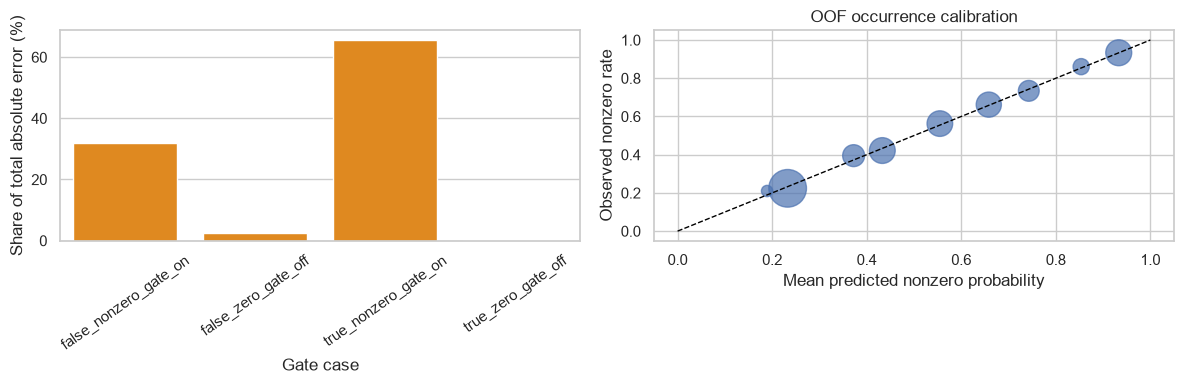

In [4]:
oof["gate_case"]=np.select([
    ~oof.actual_nonzero & ~oof.gate_nonzero,
    ~oof.actual_nonzero & oof.gate_nonzero,
    oof.actual_nonzero & ~oof.gate_nonzero,
    oof.actual_nonzero & oof.gate_nonzero],
    ["true_zero_gate_off","false_nonzero_gate_on","false_zero_gate_off","true_nonzero_gate_on"],default="unknown")
gate_table=(oof.groupby("gate_case")
    .agg(accounts=("true","size"),MAE_thb=("absolute_error","mean"),
         total_absolute_error=("absolute_error","sum"),
         mean_final_prediction=("prediction","mean")))
gate_table["row_share_pct"]=100*gate_table.accounts/len(oof)
gate_table["error_share_pct"]=100*gate_table.total_absolute_error/oof.absolute_error.sum()
display(gate_table.sort_values("error_share_pct",ascending=False).round(2))

calibration=pd.DataFrame({"probability_bin":pd.cut(oof.probability_nonzero,np.linspace(0,1,11),include_lowest=True),
                          "true_nonzero":oof.actual_nonzero,"probability":oof.probability_nonzero})
calibration=calibration.groupby("probability_bin",observed=True).agg(
    accounts=("true_nonzero","size"),observed_nonzero_rate=("true_nonzero","mean"),
    mean_probability=("probability","mean"))
display(calibration.round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.barplot(x=gate_table.index,y=gate_table.error_share_pct,color="darkorange",ax=axes[0])
axes[0].set(ylabel="Share of total absolute error (%)",xlabel="Gate case")
axes[0].tick_params(axis="x",labelrotation=35)
axes[1].plot([0,1],[0,1],linestyle="--",color="black",linewidth=1)
axes[1].scatter(calibration.mean_probability,calibration.observed_nonzero_rate,
                s=np.maximum(calibration.accounts/30,20),alpha=.7)
axes[1].set(xlabel="Mean predicted nonzero probability",ylabel="Observed nonzero rate",
            title="OOF occurrence calibration")
plt.tight_layout();plt.show()

## 4. High-spend prediction direction and component behavior

Quantify whether the selected mixture mainly underpredicts expensive spenders. Compare its gate and continuous-blend components on the same rows; this describes the tradeoff behind the final 80/20 mixture, not a new model selection.

50k+ rows: 6786 underpredicted: 0.588 median predicted/actual: 0.96


model,continuous_blend,final_mixture,gate
group,,,
50k+,20376.42,18923.14,18722.07
positive,4066.15,3793.93,3784.85
zero,1828.81,1927.89,1952.66


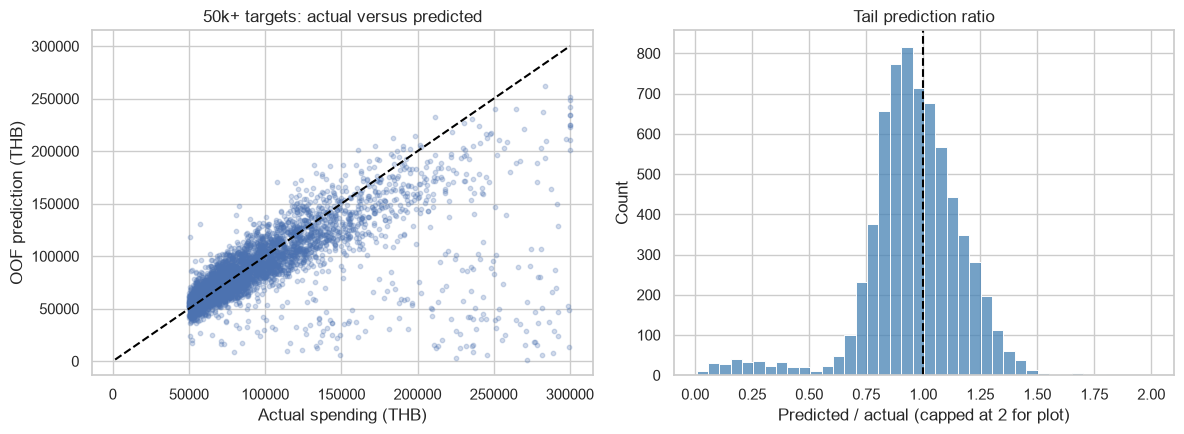

In [5]:
tail=oof[oof.true>=50000].copy()
tail["prediction_to_target"]=tail.prediction/tail.true
print("50k+ rows:",len(tail),"underpredicted:",round((tail.signed_error<0).mean(),3),
      "median predicted/actual:",round(tail.prediction_to_target.median(),3))
component_rows=[]
for group,mask in [("zero",oof.true.eq(0)),("positive",oof.true.gt(0)),
                   ("50k+",oof.true.ge(50000))]:
    sub=oof.loc[mask]
    for model,column in [("gate","gate_prediction"),("continuous_blend","blend_prediction"),
                         ("final_mixture","prediction")]:
        component_rows.append({"group":group,"model":model,"accounts":len(sub),
                               "MAE_thb":mean_absolute_error(sub.true,sub[column])})
display(pd.DataFrame(component_rows).pivot(index="group",columns="model",values="MAE_thb").round(2))

sample=tail.sample(n=min(4000,len(tail)),random_state=SEED)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].scatter(sample.true,sample.prediction,alpha=.25,s=10)
limits=[min(sample.true.min(),sample.prediction.min()),max(sample.true.max(),sample.prediction.max())]
axes[0].plot(limits,limits,color="black",linestyle="--")
axes[0].set(xlabel="Actual spending (THB)",ylabel="OOF prediction (THB)",
            title="50k+ targets: actual versus predicted")
sns.histplot(tail.prediction_to_target.clip(upper=2),bins=40,color="steelblue",ax=axes[1])
axes[1].axvline(1,color="black",linestyle="--")
axes[1].set(xlabel="Predicted / actual (capped at 2 for plot)",title="Tail prediction ratio")
plt.tight_layout();plt.show()

## 5. Locate expensive false-nonzero and tail errors in existing inputs

Slice the two costly groups by feature values that ranked highly in earlier fold-local importance checks. Bins use the development rows only and are descriptive. Show counts and error contribution before inferring a direction; no new feature or cutoff is selected here.

false_nonzero — largest error-contributing bins with at least 100 rows


,bin,accounts,MAE_thb,total_error,underprediction_rate,feature,group,error_share_within_group
12,"(1823.453, 63063.626]",2084,27525.974,5.736413e+07,0.0,prev_month_spending,false_nonzero,0.745
4,"(5204.923, 163870.532]",2079,27445.643,5.705949e+07,0.0,historical_spending,false_nonzero,0.741
58,"(715.977, 29018.57]",2024,26163.275,5.295447e+07,0.0,discount_value_interaction,false_nonzero,0.688
36,3.0,826,61399.901,5.071632e+07,0.0,segment,false_nonzero,0.659
21,"(-0.0005070000000000001, 12.193]",2738,7615.187,2.085038e+07,0.0,days_since_last_purchase,false_nonzero,0.271
22,"(12.193, 24.139]",2402,7420.774,1.782470e+07,0.0,days_since_last_purchase,false_nonzero,0.231
42,2.0,1972,8937.989,1.762571e+07,0.0,vip_status,false_nonzero,0.229
23,"(24.139, 36.158]",1849,8987.823,1.661848e+07,0.0,days_since_last_purchase,false_nonzero,0.216
43,3.0,1154,13587.348,1.567980e+07,0.0,vip_status,false_nonzero,0.204
41,1.0,2941,4668.207,1.372920e+07,0.0,vip_status,false_nonzero,0.178


50k+ — largest error-contributing bins with at least 100 rows


,bin,accounts,MAE_thb,total_error,underprediction_rate,feature,group,error_share_within_group
38,3.0,6363,18892.731,1.202144e+08,0.585,segment,50k+,0.936
8,"(5204.923, 163870.532]",6418,18112.431,1.162456e+08,0.581,historical_spending,50k+,0.905
17,"(1823.453, 63063.626]",6373,18205.180,1.160216e+08,0.581,prev_month_spending,50k+,0.904
63,"(715.977, 29018.57]",6010,18087.263,1.087045e+08,0.581,discount_value_interaction,50k+,0.847
27,"(-0.0005070000000000001, 12.193]",2127,18423.354,3.918647e+07,0.611,days_since_last_purchase,50k+,0.305
50,3.0,1836,18264.626,3.353385e+07,0.555,vip_status,50k+,0.261
28,"(12.193, 24.139]",1697,19106.474,3.242369e+07,0.559,days_since_last_purchase,50k+,0.252
49,2.0,1454,18502.994,2.690335e+07,0.607,vip_status,50k+,0.210
51,4.0,1203,19512.467,2.347350e+07,0.587,vip_status,50k+,0.183
29,"(24.139, 36.158]",1263,17965.084,2.268990e+07,0.591,days_since_last_purchase,50k+,0.177


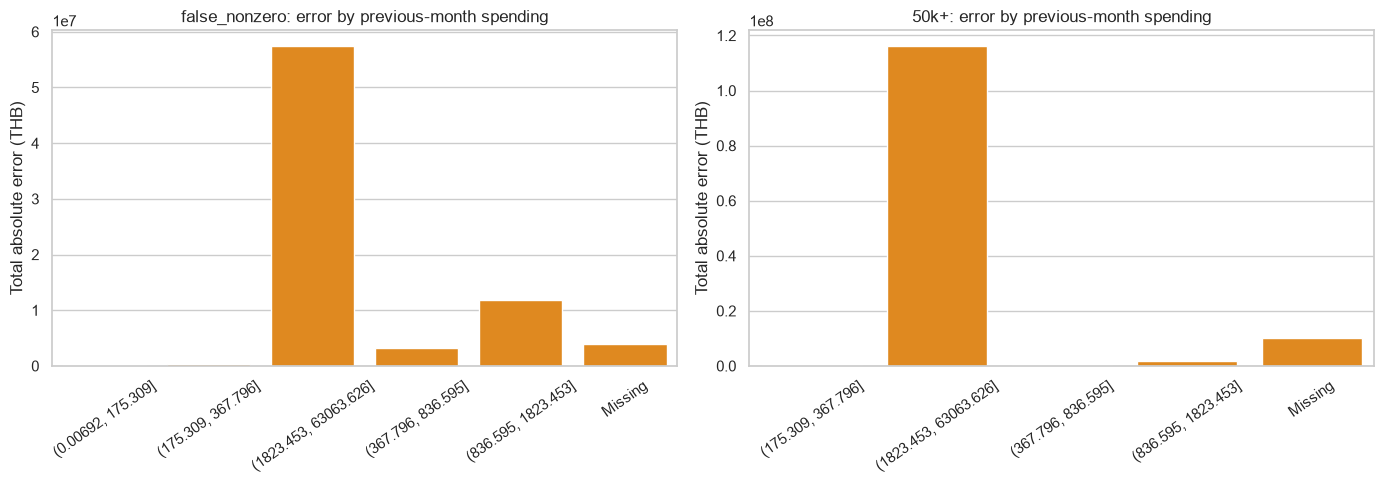

In [6]:
audit=dev[[ID,"historical_spending","prev_month_spending",
           "days_since_last_purchase","segment","vip_status","discount_value_interaction"]].copy()
for col in ["true","prediction","probability_nonzero","gate_case","absolute_error","signed_error"]:
    audit[col]=oof[col]
audit["group"]=np.select([audit.gate_case.eq("false_nonzero_gate_on"),
                           audit.true.ge(50000)],
                          ["false_nonzero","50k+"],default="other")
SLICE_FEATURES=["historical_spending","prev_month_spending","days_since_last_purchase",
                "segment","vip_status","discount_value_interaction"]
def feature_bin(series):
    if series.dropna().nunique()<=8:
        return series.astype("string").fillna("Missing")
    return pd.qcut(series,q=5,duplicates="drop").astype("string").fillna("Missing")
slice_rows=[]
for feature in SLICE_FEATURES:
    bins=feature_bin(audit[feature])
    for group in ["false_nonzero","50k+"]:
        sub=audit.loc[audit.group.eq(group)].copy()
        sub["bin"]=bins.loc[sub.index]
        table=sub.groupby("bin",observed=True).agg(
            accounts=("true","size"),MAE_thb=("absolute_error","mean"),
            total_error=("absolute_error","sum"),
            underprediction_rate=("signed_error",lambda x:(x<0).mean())).reset_index()
        table["feature"],table["group"]=feature,group
        table["error_share_within_group"]=table.total_error/sub.absolute_error.sum()
        slice_rows.append(table)
slice_table=pd.concat(slice_rows,ignore_index=True)
for group in ["false_nonzero","50k+"]:
    print(group,"— largest error-contributing bins with at least 100 rows")
    display(slice_table.loc[(slice_table.group==group)&(slice_table.accounts>=100)]
            .sort_values("total_error",ascending=False).head(15).round(3))

fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,group in zip(axes,["false_nonzero","50k+"]):
    table=slice_table[(slice_table.group==group)&(slice_table.feature=="prev_month_spending")]
    sns.barplot(data=table,x="bin",y="total_error",color="darkorange",ax=ax)
    ax.set(title=f"{group}: error by previous-month spending",ylabel="Total absolute error (THB)",xlabel="")
    ax.tick_params(axis="x",labelrotation=35)
plt.tight_layout();plt.show()

## Readout

Record the dominant error groups, whether expensive zero-target predictions and large positive underpredictions occupy different regions, and one testable hypothesis for the next EDA dataset. OOF patterns are exploratory and the old holdout remains reused. No dataset or model is written by this analysis notebook.